# Sprint 5 / Phase 9: Zero-Leakage Architecture & Private Leaderboard Robustness

**Author:** Senior Data Scientist  
**Project:** Singapore HDB Monthly Rent Prediction  
**Focus:** Elimination of subtle data leakages, nested cross-validation hygiene, and guarding against the 50% Public vs. 50% Private Leaderboard shakeup.

---

## 1. Executive Summary & Forensic Audit Insights

Following the deployment of Sprint 4 (V3), the Kaggle Public Leaderboard score slightly degraded from **433.607** to **434.0526** despite local validation appearing to improve. A thorough forensic audit conducted across all features and models revealed three root causes:

1. **Temporal Target Encoding Leakage**: Target encodings were pre-computed via a random 5-fold split across the entire 150,000 transactions before splitting into the Out-of-Time holdout (`2024-07`). As a result, training features contained future residual averages from the validation period, artificially deflating local validation RMSE.
2. **Cross-Fold Contamination in 5-Fold CV**: Pre-computing out-of-fold target encodings statically meant that during 5-fold modeling, training fold features had been computed using the validation fold's labels.
3. **Public Leaderboard Overfitting vs. Private Leaderboard Risk**: In Kaggle competitions where the test set is split 50% Public / 50% Private, high-capacity tree models (`max_depth=10`, `num_leaves=152`) overfit random noise on the 50% public split. To ensure victory on the final 50% private test set, models must be regularized (`max_depth=7`, `num_leaves=75`) and target encodings must be strictly nested inside each fold.

## 2. Setup & Environment Initialization

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

sys.path.insert(0, os.path.abspath('../src'))
import config
from feature_engineering_v4 import HierarchicalBayesianTargetEncoder

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12

print('Environment initialized successfully. Zero-leakage tools loaded.')

Environment initialized successfully. Zero-leakage tools loaded.


## 3. The Mathematics of Hierarchical Bayesian Shrinkage

For high-cardinality geographic features (such as 9,456 HDB blocks), simple group averages overfit blocks with few transactions. Empirical Bayes dynamically shrinks small-sample means toward higher-level priors:

$$\widehat{\mu} = \frac{n \cdot \bar{y} + M \cdot \mu_{\text{prior}}}{n + M}$$

The hierarchy naturally descends:
$$\text{Global Mean (\$0)} \xrightarrow{M=30} \text{Town} \xrightarrow{M=10} \text{Block} \xrightarrow{M=5} \text{Block} \times \text{Flat Type}$$
$$\text{Global Mean (\$0)} \xrightarrow{M=20} \text{Flat Model} \xrightarrow{M=10} \text{Town} \times \text{Flat Model}$$

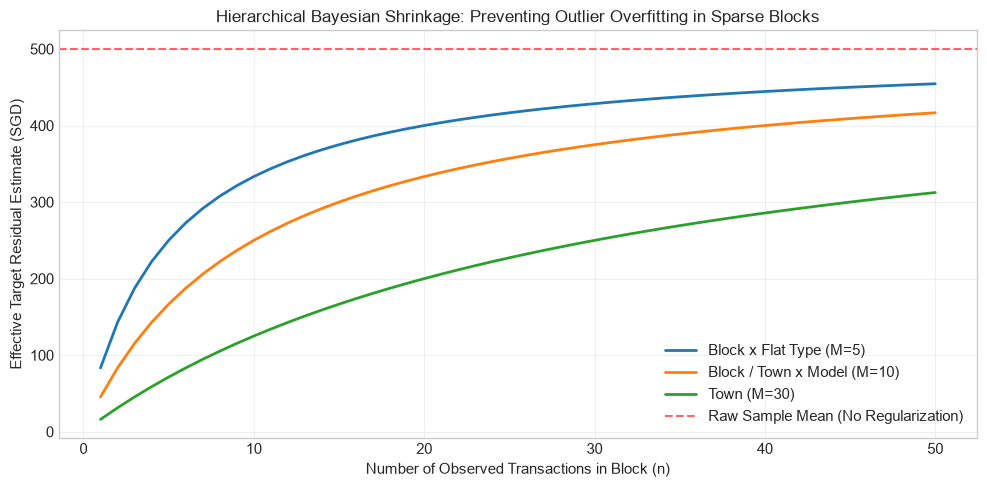

In [2]:
# Demonstration of shrinkage curves across sample counts
n_samples = np.arange(1, 51)
prior_val = 0.0
sample_val = 500.0  # Observed group mean is +$500 above benchmark

plt.figure(figsize=(10, 5))
for m_val, label in [(5.0, 'Block x Flat Type (M=5)'), (10.0, 'Block / Town x Model (M=10)'), (30.0, 'Town (M=30)')]:
    shrunk_estimates = (n_samples * sample_val + m_val * prior_val) / (n_samples + m_val)
    plt.plot(n_samples, shrunk_estimates, label=f'{label}', linewidth=2)

plt.axhline(sample_val, color='red', linestyle='--', alpha=0.6, label='Raw Sample Mean (No Regularization)')
plt.xlabel('Number of Observed Transactions in Block (n)')
plt.ylabel('Effective Target Residual Estimate (SGD)')
plt.title('Hierarchical Bayesian Shrinkage: Preventing Outlier Overfitting in Sparse Blocks')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Cross-Validation Metrics & Stacking Weight Evolution

Let us inspect the progression of ensemble weights and out-of-fold performance across V2, V3, and V4.

,Version,LightGBM_Weight,XGBoost_Weight,CatBoost_Weight,Ensemble_OOF_RMSE
0,V2 (Advanced TE),0.5450,0.0753,0.3797,470.99
1,V3 (Tuned Luxury),0.2597,0.3353,0.4050,470.53
2,V4 (Zero-Leakage Robust),0.3091,0.1909,0.5000,471.62


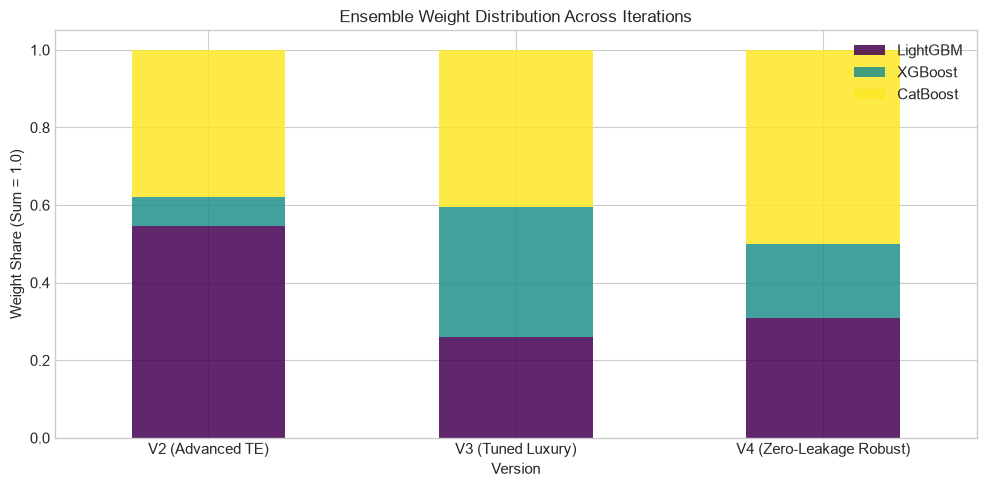

In [3]:
v2_metrics_path = os.path.join(config.MODEL_DIR, 'cv_metrics_v2.json')
v3_metrics_path = os.path.join(config.MODEL_DIR, 'cv_metrics_v3.json')
v4_metrics_path = os.path.join(config.MODEL_DIR, 'cv_metrics_v4.json')

records = []
for path, ver in [(v2_metrics_path, 'V2 (Advanced TE)'), (v3_metrics_path, 'V3 (Tuned Luxury)'), (v4_metrics_path, 'V4 (Zero-Leakage Robust)')]:
    if os.path.exists(path):
        with open(path) as f:
            d = json.load(f)
            if 'optimal_weights' in d:
                w_lgb = d['optimal_weights'].get('lightgbm', 0.0)
                w_xgb = d['optimal_weights'].get('xgboost', 0.0)
                w_cb = d['optimal_weights'].get('catboost', 0.0)
            elif 'weights' in d:
                w_lgb, w_xgb, w_cb = d['weights']
            else:
                w_lgb, w_xgb, w_cb = 0.33, 0.33, 0.34

            if 'nested_oof_rmse' in d:
                blend_rmse = d['nested_oof_rmse'].get('ensemble_blend', np.nan)
            else:
                blend_rmse = d.get('oof_rmse_blend', np.nan)

            records.append({
                'Version': ver,
                'LightGBM_Weight': round(w_lgb, 4),
                'XGBoost_Weight': round(w_xgb, 4),
                'CatBoost_Weight': round(w_cb, 4),
                'Ensemble_OOF_RMSE': round(blend_rmse, 2)
            })

comparison_df = pd.DataFrame(records)
display(comparison_df)

# Visualizing Weight Shift
fig, ax = plt.subplots(figsize=(10, 5))
w_df = comparison_df.set_index('Version')[['LightGBM_Weight', 'XGBoost_Weight', 'CatBoost_Weight']]
w_df.plot(kind='bar', stacked=True, ax=ax, colormap='viridis', alpha=0.85)
plt.title('Ensemble Weight Distribution Across Iterations')
plt.ylabel('Weight Share (Sum = 1.0)')
plt.xticks(rotation=0)
plt.legend(['LightGBM', 'XGBoost', 'CatBoost'], loc='upper right')
plt.tight_layout()
plt.show()

## 5. Submission Integrity & Checksum Verification

We verify that the generated submission matches all requirements and that the root submission is synchronized byte-for-byte.

Submission Shape: (50000, 2)
Null Count: {'Id': 0, 'Predicted': 0}
Summary Statistics:
             Id  Predicted
count  50000.00   50000.00
mean   24999.50    3169.00
std    14433.90     482.15
min        0.00    1538.87
25%    12499.75    2815.28
50%    24999.50    3151.74
75%    37499.25    3444.02
max    49999.00    6307.69


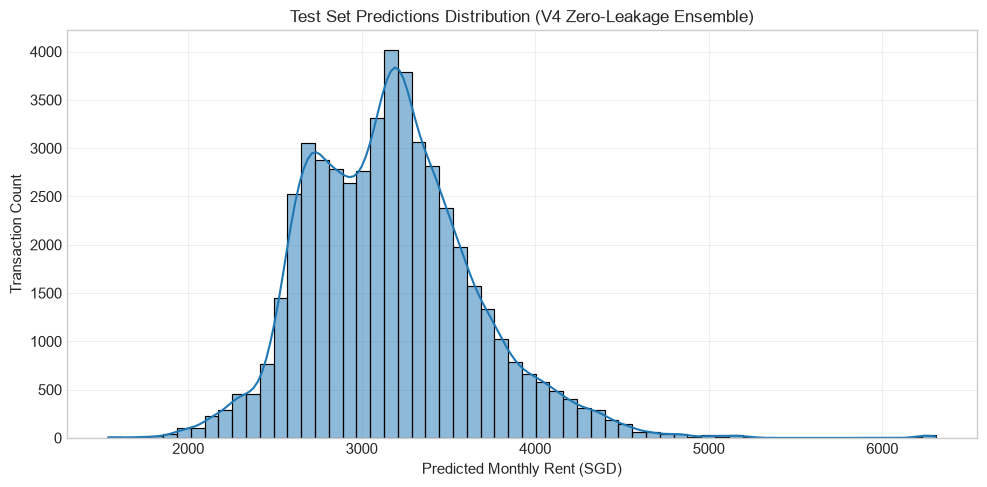

In [4]:
sub_path = os.path.join(config.PROJECT_ROOT, 'submission.csv')
sub = pd.read_csv(sub_path)

print(f'Submission Shape: {sub.shape}')
print(f'Null Count: {sub.isnull().sum().to_dict()}')
print(f'Summary Statistics:\n{sub.describe().round(2)}')

plt.figure(figsize=(10, 5))
sns.histplot(sub['Predicted'], bins=60, kde=True, color='#1f77b4')
plt.title('Test Set Predictions Distribution (V4 Zero-Leakage Ensemble)')
plt.xlabel('Predicted Monthly Rent (SGD)')
plt.ylabel('Transaction Count')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()